In [ ]:
import os

os.makedirs("figures", exist_ok=True)

In [1]:
import os
import numpy as np
import pandas as pd
import geopandas as gpd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib as mpl

from scipy.stats import pearsonr, spearmanr
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import PercentFormatter, StrMethodFormatter

# Colour palettes
sea_glass = LinearSegmentedColormap.from_list(
    "sea_glass",
    ["#F0F6F2", "#B2DBBF", "#70C1B3", "#247BA0", "#153B50"]
)

risk_cmap = LinearSegmentedColormap.from_list(
    "risk",
    ["#FBF3E9", "#F5DCC1", "#EAB78E", "#EE926F", "#CB5039"]
)

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.titlecolor": "#153B50",
    "figure.dpi": 150
})

source = "Source: London Airbnb dataset | September 2026"

# Load Airbnb data
file = "20260917-London-listings.csv.gz"
url = f"https://orca.casa.ucl.ac.uk/~jreades/data/{file}"

if not os.path.exists(file):
    pd.read_csv(url, low_memory=False).to_csv(file, index=False)

columns = [
    "id", "host_id", "longitude", "latitude",
    "room_type", "neighbourhood_cleansed",
    "estimated_occupancy_l365d"
]

df = pd.read_csv(file, usecols=columns)

# Data quality checks
print("Original listings:", len(df))
print("Duplicate IDs:", df["id"].duplicated().sum())
print(df.isna().sum())

assert df["id"].is_unique
assert not df.isna().any().any()

# Load borough boundaries
borough_url = (
    "https://gis.london.gov.uk/arcgis/rest/services/apps/"
    "BIDs_service_02/MapServer/6/query?"
    "where=1%3D1&outFields=NAME&outSR=4326&f=geojson"
)

boroughs = gpd.read_file(borough_url).reset_index(drop=True)

# Convert listings to spatial points
points = gpd.GeoDataFrame(
    df,
    geometry=gpd.points_from_xy(
        df["longitude"], df["latitude"]
    ),
    crs="EPSG:4326"
)

# Spatial join
joined = gpd.sjoin(
    points,
    boroughs[["geometry"]].to_crs(points.crs),
    how="left",
    predicate="within"
)

assert len(joined) == len(df)
assert joined["id"].is_unique
assert joined["index_right"].notna().all()

df = df.merge(
    joined[["id", "index_right"]],
    on="id",
    validate="one_to_one"
).rename(columns={"index_right": "borough_index"})

boroughs_map = boroughs.to_crs("EPSG:27700")

print("Matched listings:", len(df))
print("Number of areas:", len(boroughs))

Original listings: 91954
Duplicate IDs: 0
id                           0
host_id                      0
neighbourhood_cleansed       0
latitude                     0
longitude                    0
room_type                    0
estimated_occupancy_l365d    0
dtype: int64
Matched listings: 91954
Number of areas: 33


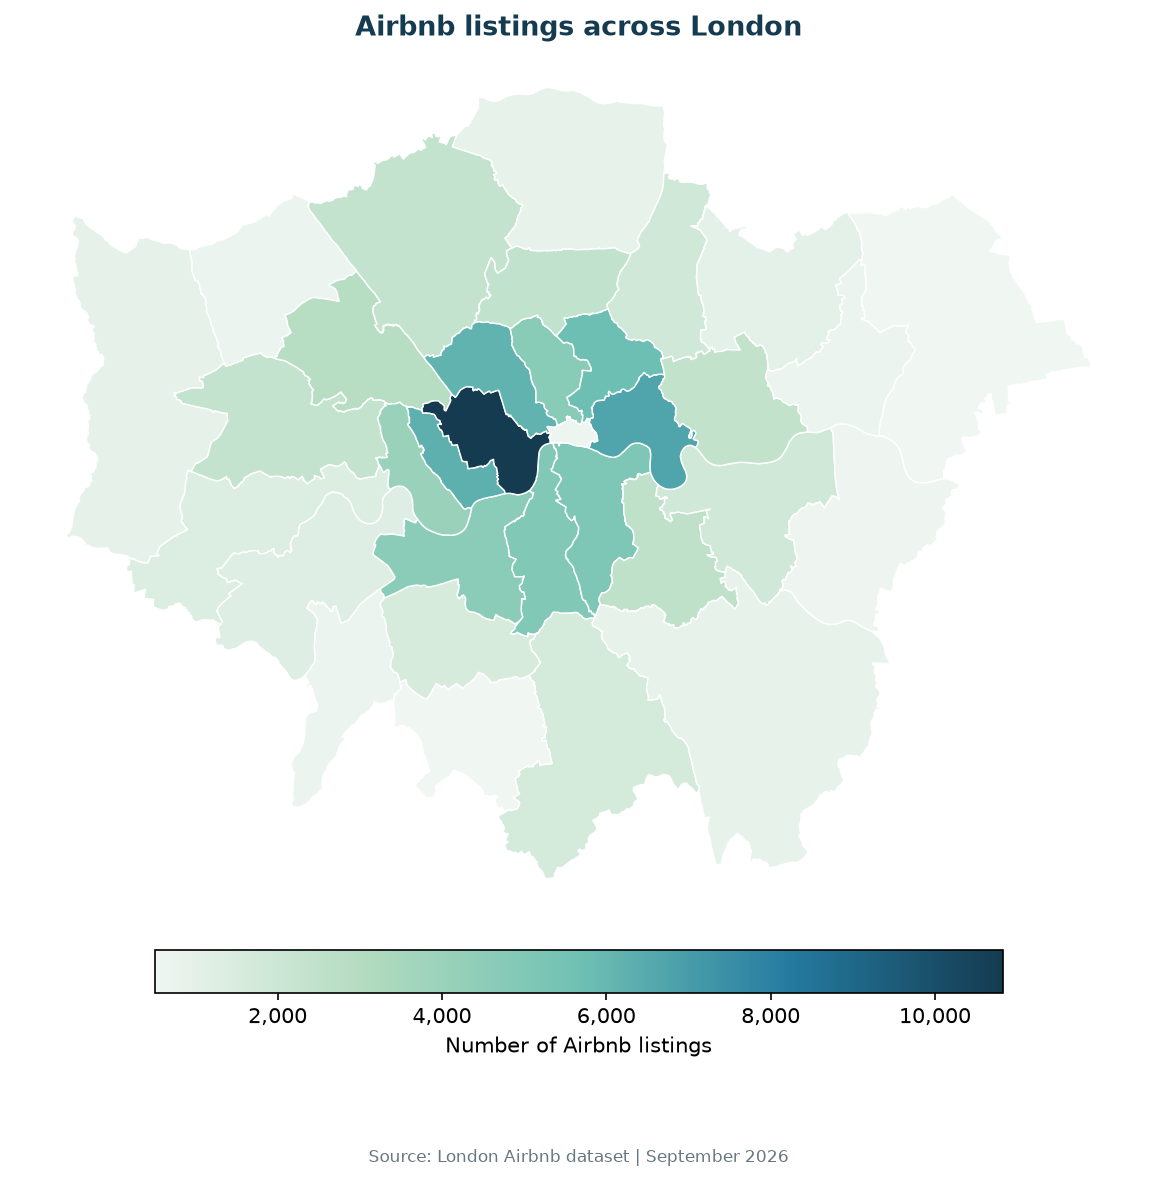

In [9]:
# Count listings by borough
boroughs_map["listing_count"] = (
    df.groupby("borough_index").size()
    .reindex(boroughs_map.index, fill_value=0)
)

assert boroughs_map["listing_count"].sum() == len(df)

# Draw map
fig, ax = plt.subplots(figsize=(9, 8))

boroughs_map.plot(
    column="listing_count",
    cmap=sea_glass,
    edgecolor="white",
    linewidth=0.7,
    legend=True,
    legend_kwds={
        "orientation": "horizontal",
        "label": "Number of Airbnb listings",
        "shrink": 0.65,
        "pad": 0.03,
        "format": StrMethodFormatter("{x:,.0f}")
    },
    ax=ax
)

ax.set_title("Airbnb listings across London")
ax.set_axis_off()

fig.text(
    0.5, 0.025, source,
    ha="center", fontsize=8, color="#667780"
)

plt.tight_layout(rect=[0, 0.05, 1, 1])
fig.savefig(
    "figures/Fig01_spatial_distribution.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

In [8]:
import os

os.makedirs("figures", exist_ok=True)
os.makedirs("results", exist_ok=True)

print("Current directory:", os.getcwd())
print("Figures folder exists:", os.path.exists("figures"))
print("Results folder exists:", os.path.exists("results"))

Current directory: /home/jovyan/work/FSDS_group_project
Figures folder exists: True
Results folder exists: True


,host_scale,host_number,listing_number,host_share,listing_share
0,1 listing,40964,40964,79.78,44.55
1,2–4 listings,8139,19854,15.85,21.59
2,5–9 listings,1355,8559,2.64,9.31
3,10+ listings,890,22577,1.73,24.55


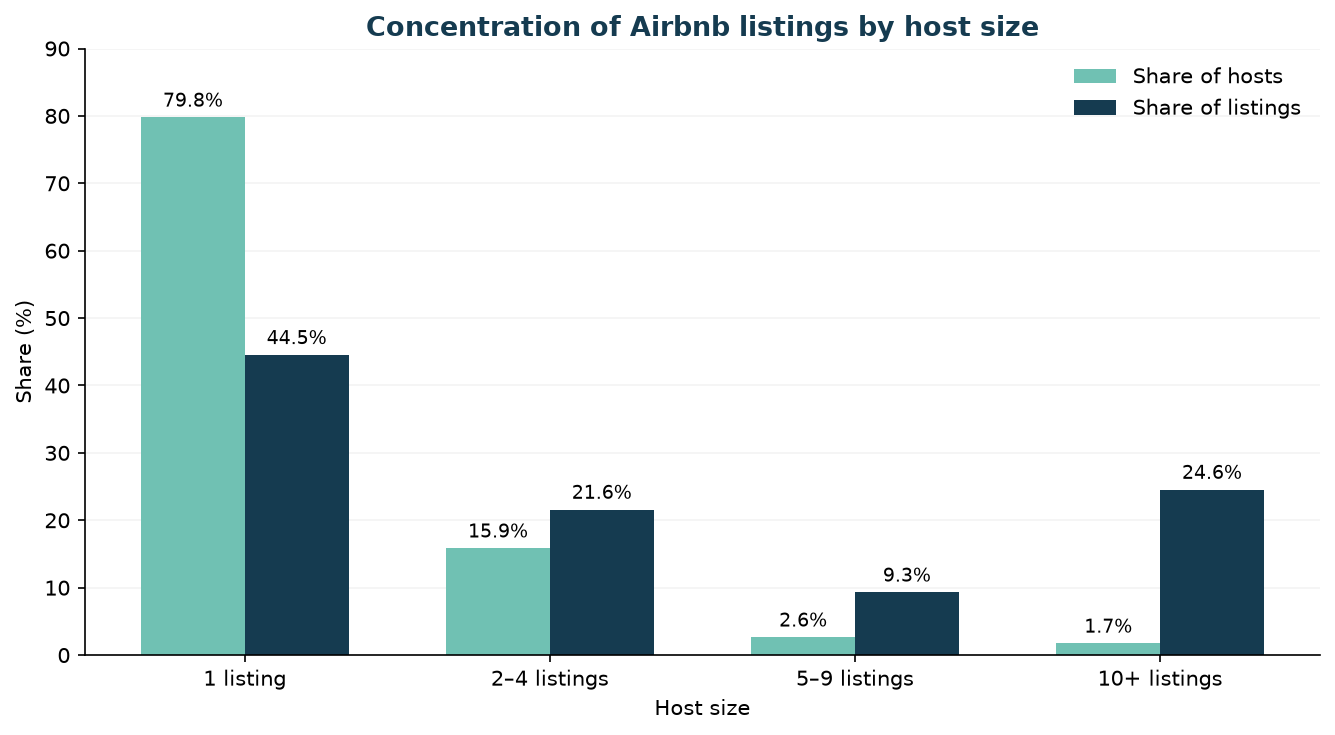

In [12]:
# Count listings per host
host_counts = (
    df.groupby("host_id")["id"]
    .nunique()
    .reset_index(name="listing_count")
)

scale_labels = [
    "1 listing",
    "2–4 listings",
    "5–9 listings",
    "10+ listings"
]

# Classify host size
host_counts["host_scale"] = pd.cut(
    host_counts["listing_count"],
    bins=[0, 1, 4, 9, np.inf],
    labels=scale_labels
)

# Summary statistics
host_summary = (
    host_counts.groupby("host_scale", observed=True)
    .agg(
        host_number=("host_id", "count"),
        listing_number=("listing_count", "sum")
    )
    .reset_index()
)

host_summary["host_share"] = (
    host_summary["host_number"] / len(host_counts) * 100
)

host_summary["listing_share"] = (
    host_summary["listing_number"] / len(df) * 100
)

display(host_summary.round(2))

# Join host classification to listings
df_hosts = df.merge(
    host_counts,
    on="host_id",
    how="left",
    validate="many_to_one"
)

df_hosts["is_multi_host"] = df_hosts["listing_count"] > 1
df_hosts["is_large_host"] = df_hosts["listing_count"] >= 10

# Grouped bar chart
fig, ax = plt.subplots(figsize=(9, 5))

x = np.arange(len(host_summary))
width = 0.34

bars1 = ax.bar(
    x - width / 2,
    host_summary["host_share"],
    width,
    color="#70C1B3",
    label="Share of hosts"
)

bars2 = ax.bar(
    x + width / 2,
    host_summary["listing_share"],
    width,
    color="#153B50",
    label="Share of listings"
)

for bars in [bars1, bars2]:
    ax.bar_label(bars, fmt="%.1f%%", padding=3, fontsize=9)

ax.set_xticks(x, host_summary["host_scale"])
ax.set_ylabel("Share (%)")
ax.set_xlabel("Host size")
ax.set_ylim(0, 90)
ax.set_title("Concentration of Airbnb listings by host size")

ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", alpha=0.15)
ax.set_axisbelow(True)
ax.legend(frameon=False)

plt.tight_layout()
fig.savefig(
    "figures/Fig02_host_concentration.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

In [10]:
os.listdir("figures")

['Fig01_spatial_distribution.png']

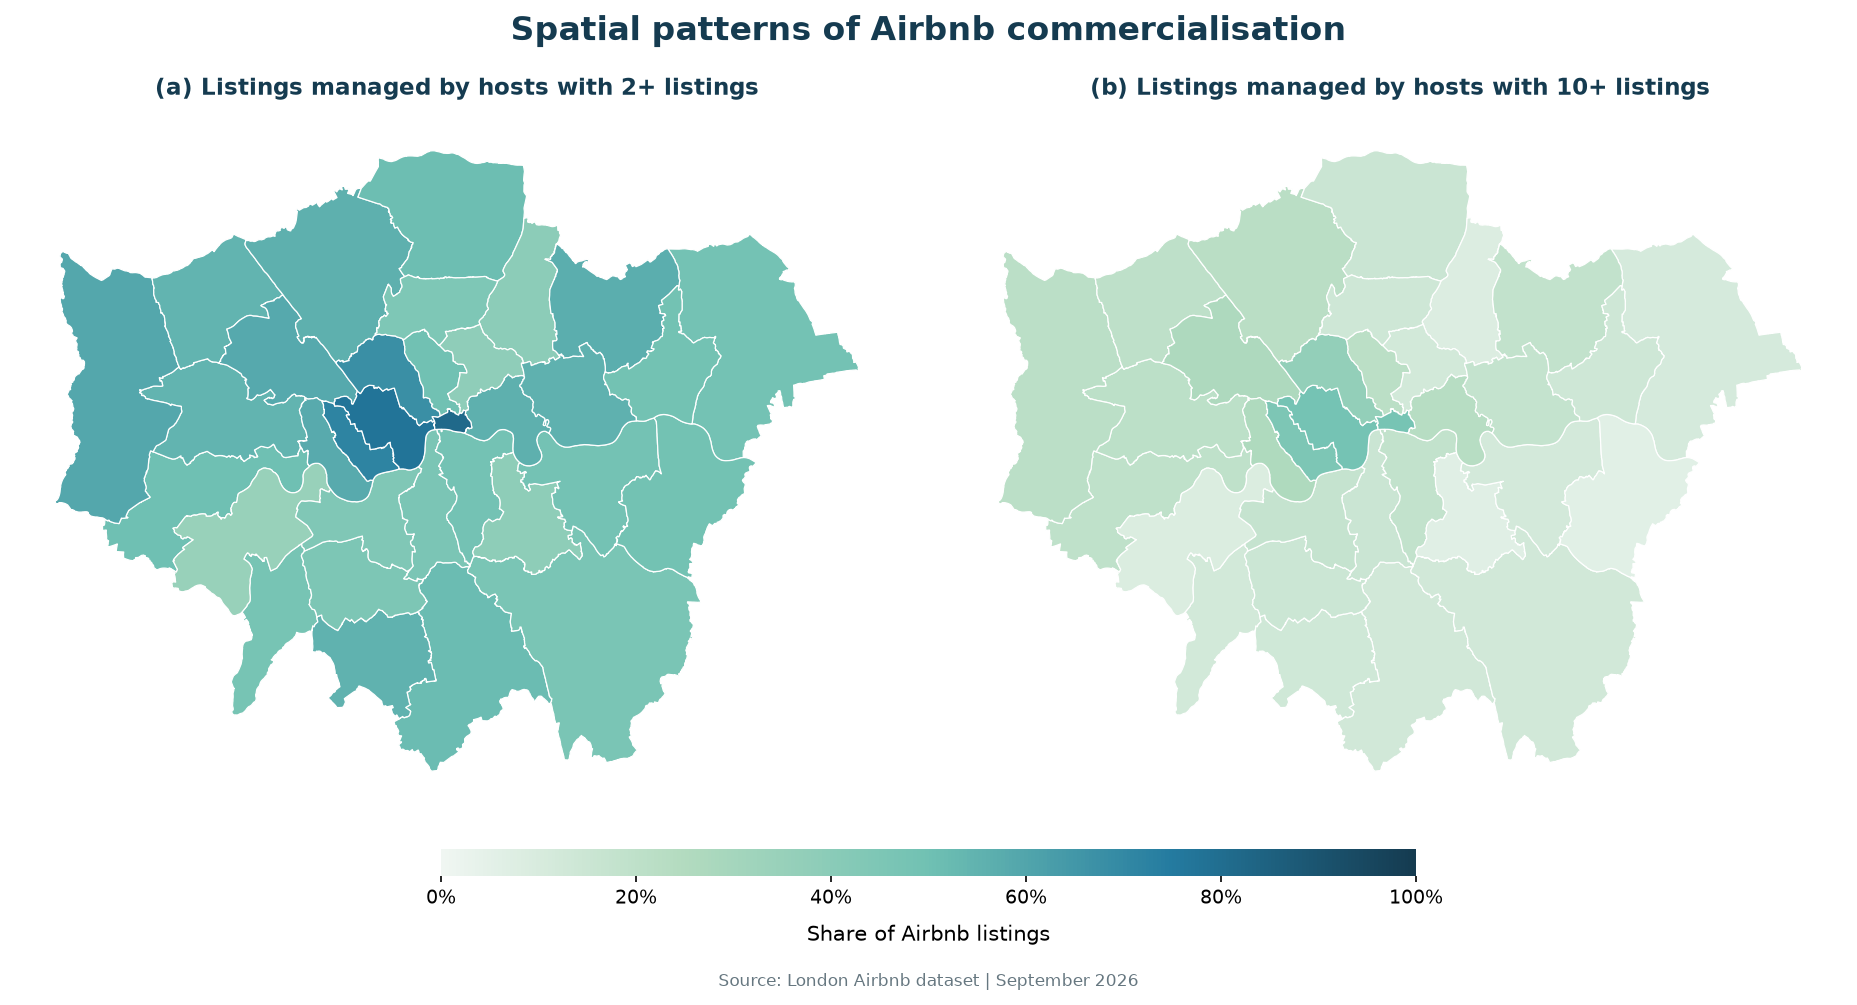

In [16]:
import os

os.makedirs("figures", exist_ok=True)

# Borough-level host concentration
borough_host_summary = (
    df_hosts.groupby("borough_index")
    .agg(
        total_listings=("id", "count"),
        multi_listings=("is_multi_host", "sum"),
        large_listings=("is_large_host", "sum")
    )
)

# Calculate percentage shares
for category in ["multi", "large"]:
    borough_host_summary[f"{category}_share"] = (
        borough_host_summary[f"{category}_listings"]
        / borough_host_summary["total_listings"] * 100
    )

borough_host_summary["borough_name"] = (
    borough_host_summary.index.map(boroughs["name"])
)

commercial_map = boroughs_map.join(borough_host_summary)

# Create two-panel map
fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 7),
    dpi=150
)

# Adjust figure layout
fig.subplots_adjust(
    left=0.03,
    right=0.97,
    top=0.85,
    bottom=0.20,
    wspace=0.06
)

# Shared colour scale
norm = mpl.colors.Normalize(vmin=0, vmax=100)

# Draw maps
for ax, column, title in zip(
    axes,
    ["multi_share", "large_share"],
    [
        "(a) Listings managed by hosts with 2+ listings",
        "(b) Listings managed by hosts with 10+ listings"
    ]
):
    commercial_map.plot(
        column=column,
        cmap=sea_glass,
        norm=norm,
        edgecolor="white",
        linewidth=0.6,
        ax=ax
    )

    ax.set_title(
        title,
        fontsize=11,
        loc="center",
        color="#153B50",
        pad=12
    )

    ax.set_aspect("equal")
    ax.set_axis_off()

# Shared colour bar
sm = mpl.cm.ScalarMappable(
    cmap=sea_glass,
    norm=norm
)

sm.set_array([])

# Fixed colour bar position
cax = fig.add_axes([0.25, 0.13, 0.50, 0.025])

cbar = fig.colorbar(
    sm,
    cax=cax,
    orientation="horizontal",
    ticks=[0, 20, 40, 60, 80, 100]
)

cbar.set_label(
    "Share of Airbnb listings",
    fontsize=10,
    labelpad=8
)

cbar.ax.xaxis.set_major_formatter(
    PercentFormatter(xmax=100)
)

cbar.ax.tick_params(
    labelsize=9,
    length=3
)

cbar.outline.set_visible(False)

# Main title
fig.suptitle(
    "Spatial patterns of Airbnb commercialisation",
    fontsize=16,
    fontweight="bold",
    color="#153B50",
    y=0.95
)

# Data source
fig.text(
    0.5, 0.025,
    source,
    ha="center",
    fontsize=8,
    color="#667780"
)

# Save high-resolution figure
fig.savefig(
    "figures/Fig03_commercialisation.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

Entire-home listings: 61074
Zero nights: 27672
255 nights: 3666


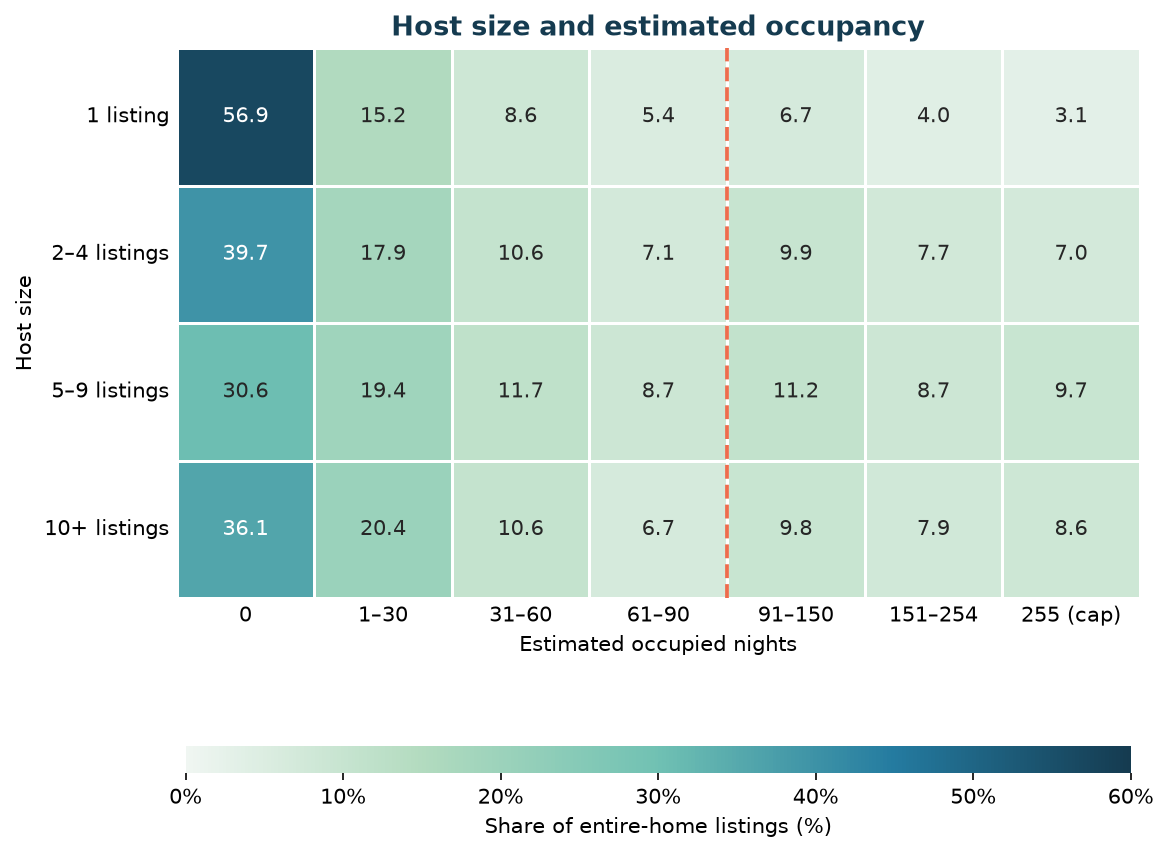

Listings exceeding 90 nights: 12709
London-wide share: 20.81%


,total_listings,over_90_count,risk_share
host_scale,,,
1 listing,26624,3662,13.75
2–4 listings,10594,2607,24.61
5–9 listings,5390,1599,29.67
10+ listings,18466,4841,26.22


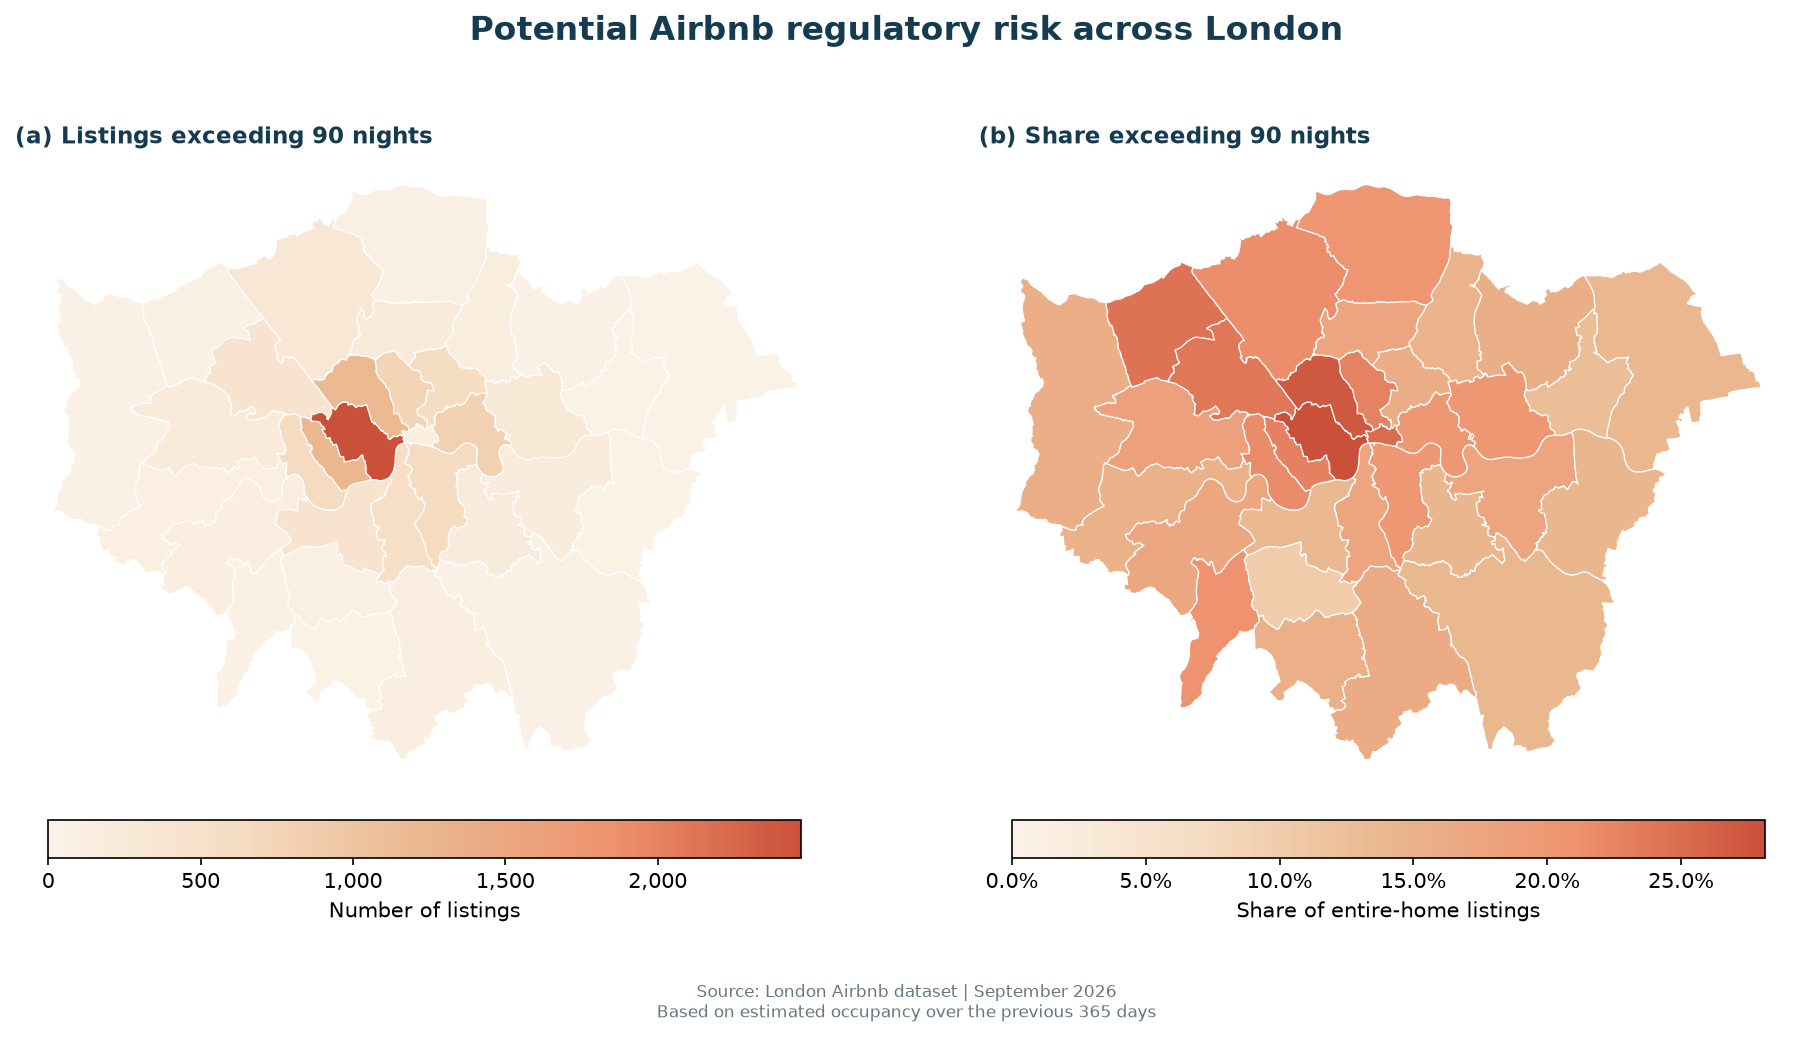

In [17]:
# Select entire-home listings
risk_df = df_hosts[
    df_hosts["room_type"] == "Entire home/apt"
].copy()

occ = risk_df["estimated_occupancy_l365d"]

# Data distribution checks
print("Entire-home listings:", len(risk_df))
print("Zero nights:", (occ == 0).sum())
print("255 nights:", (occ == 255).sum())

assert occ.between(0, 255).all()

# Occupancy classification
labels = [
    "0", "1–30", "31–60", "61–90",
    "91–150", "151–254", "255 (cap)"
]

risk_df["occupancy_group"] = pd.cut(
    occ,
    bins=[-1, 0, 30, 60, 90, 150, 254, 255],
    labels=labels
)

heat_data = pd.crosstab(
    risk_df["occupancy_group"],
    risk_df["host_scale"],
    normalize="columns"
).reindex(
    index=labels,
    columns=scale_labels,
    fill_value=0
) * 100

# Occupancy heatmap
fig, ax = plt.subplots(figsize=(9, 6))

sns.heatmap(
    heat_data.T,
    cmap=sea_glass,
    square=True,
    annot=True,
    fmt=".1f",
    vmin=0,
    vmax=60,
    linewidths=0.6,
    linecolor="white",
    cbar_kws={
        "label": "Share of entire-home listings (%)",
        "orientation": "horizontal",
        "shrink": 0.75,
        "aspect": 35,
        "pad": 0.18,
        "format": PercentFormatter(xmax=100)
    },
    ax=ax
)

ax.axvline(
    4,
    color="#EE6C4D",
    linestyle="--",
    linewidth=1.8
)

ax.set_title("Host size and estimated occupancy")
ax.set_xlabel("Estimated occupied nights")
ax.set_ylabel("Host size")
ax.tick_params(axis="both", length=0)

plt.xticks(rotation=0)
plt.yticks(rotation=0)
plt.tight_layout()

fig.savefig(
    "figures/Fig04_occupancy_heatmap.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# Potential regulatory risk
risk_df["over_90"] = occ > 90

london_risk = risk_df["over_90"].mean() * 100

print("Listings exceeding 90 nights:", risk_df["over_90"].sum())
print(f"London-wide share: {london_risk:.2f}%")

risk_summary = (
    risk_df.groupby("host_scale", observed=True)
    .agg(
        total_listings=("id", "count"),
        over_90_count=("over_90", "sum")
    )
)

risk_summary["risk_share"] = (
    risk_summary["over_90_count"]
    / risk_summary["total_listings"] * 100
)

display(risk_summary.round(2))

# Borough-level regulatory risk
borough_risk = (
    risk_df.groupby("borough_index")
    .agg(
        entire_home_count=("id", "count"),
        over_90_count=("over_90", "sum")
    )
)

borough_risk["risk_share"] = (
    borough_risk["over_90_count"]
    / borough_risk["entire_home_count"] * 100
)

risk_map = boroughs_map.join(borough_risk)

# Regulatory risk maps
fig, axes = plt.subplots(1, 2, figsize=(13, 7))

for ax, column, title, unit, formatter in zip(
    axes,
    ["over_90_count", "risk_share"],
    [
        "(a) Listings exceeding 90 nights",
        "(b) Share exceeding 90 nights"
    ],
    [
        "Number of listings",
        "Share of entire-home listings"
    ],
    [
        StrMethodFormatter("{x:,.0f}"),
        PercentFormatter(xmax=100)
    ]
):
    risk_map.plot(
        column=column,
        cmap=risk_cmap,
        vmin=0,
        edgecolor="white",
        linewidth=0.6,
        legend=True,
        legend_kwds={
            "orientation": "horizontal",
            "label": unit,
            "shrink": 0.8,
            "pad": 0.04,
            "format": formatter
        },
        ax=ax
    )

    ax.set_title(title, fontsize=11, loc="left")
    ax.set_axis_off()

fig.suptitle(
    "Potential Airbnb regulatory risk across London",
    fontsize=16,
    fontweight="bold",
    color="#153B50"
)

fig.text(
    0.5, 0.025,
    source + "\nBased on estimated occupancy over the previous 365 days",
    ha="center",
    fontsize=8,
    color="#667780"
)

plt.tight_layout(rect=[0, 0.08, 1, 0.92])

fig.savefig(
    "figures/Fig05_regulatory_risk.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

,Variable,Pearson r,Pearson p,Spearman rho,Spearman p,Excluding four areas
0,multi_share,0.703424,0.000005,0.622995,0.000108,0.458781
1,large_share,0.759476,0.000000,0.699198,0.000006,0.599626


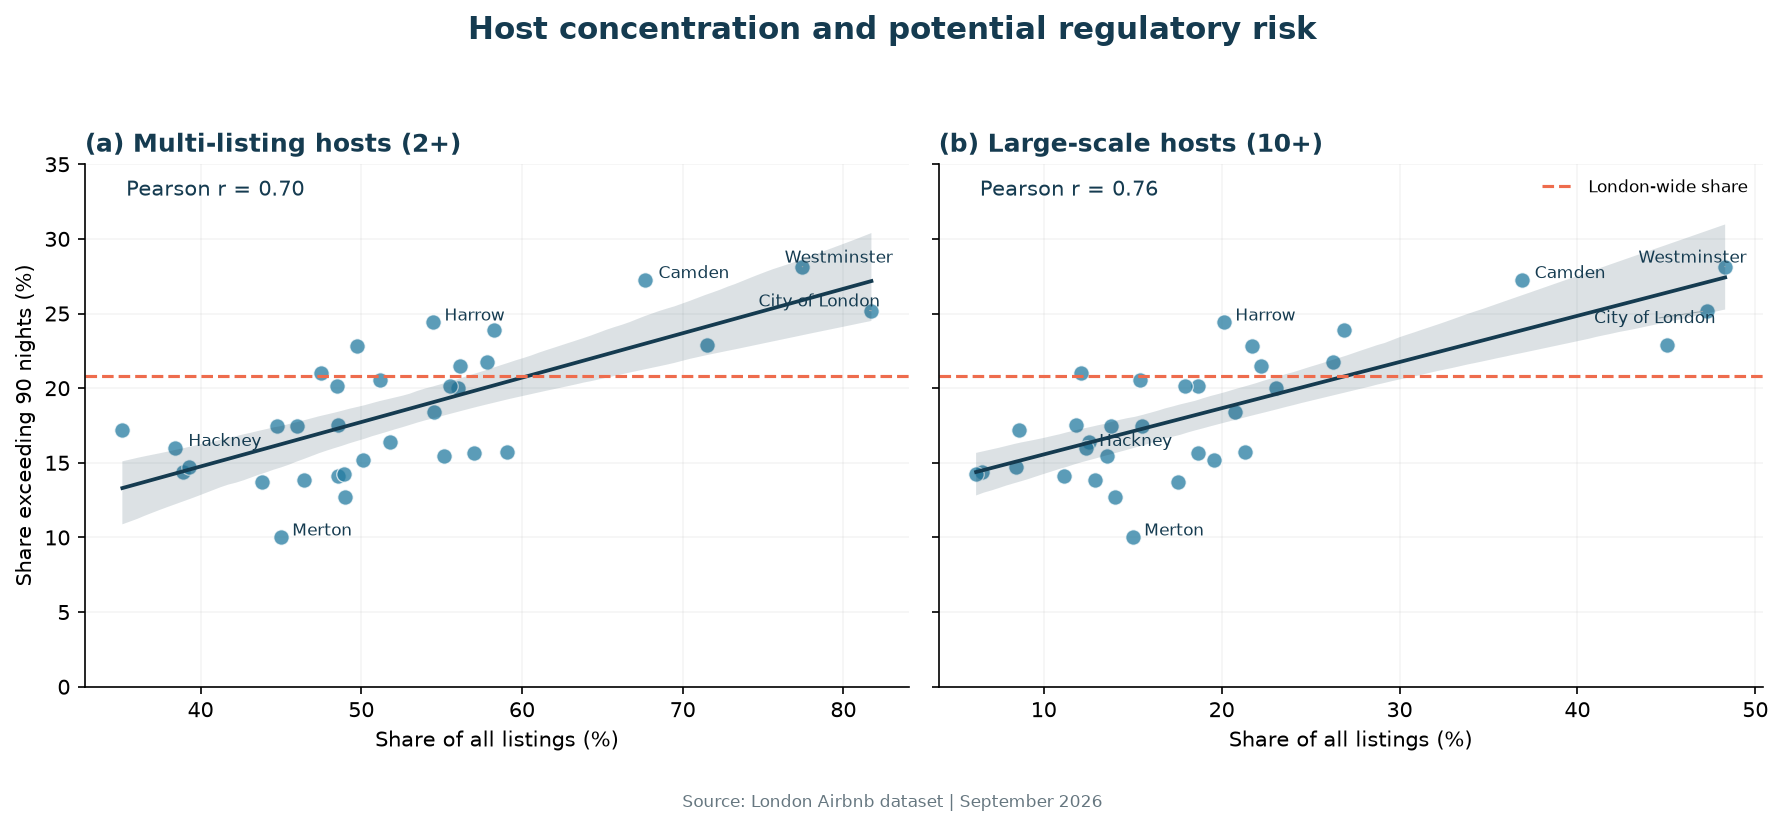

In [11]:
from adjustText import adjust_text

# Combine borough-level statistics
relationship_df = borough_host_summary.join(
    borough_risk
)

variables = ["multi_share", "large_share"]

# Correlation analysis
results = []

excluded = [
    "Westminster",
    "City of London",
    "Kensington and Chelsea",
    "Camden"
]

sensitivity_df = relationship_df[
    ~relationship_df["borough_name"].isin(excluded)
]

for variable in variables:

    r, p = pearsonr(
        relationship_df[variable],
        relationship_df["risk_share"]
    )

    rho, p_rank = spearmanr(
        relationship_df[variable],
        relationship_df["risk_share"]
    )

    results.append({
        "Variable": variable,
        "Pearson r": r,
        "Pearson p": p,
        "Spearman rho": rho,
        "Spearman p": p_rank,
        "Excluding four areas": sensitivity_df[
            variable
        ].corr(sensitivity_df["risk_share"])
    })

correlation_summary = pd.DataFrame(results)

display(correlation_summary.round(6))

# Regression plots
fig, axes = plt.subplots(
    1, 2, figsize=(12, 5.5), sharey=True
)

for ax, variable, title in zip(
    axes,
    variables,
    [
        "(a) Multi-listing hosts (2+)",
        "(b) Large-scale hosts (10+)"
    ]
):
    sns.regplot(
        data=relationship_df,
        x=variable,
        y="risk_share",
        ci=95,
        seed=42,
        scatter_kws={
            "s": 55,
            "alpha": 0.75,
            "color": "#247BA0",
            "edgecolors": "white",
            "linewidths": 0.6
        },
        line_kws={
            "color": "#153B50",
            "linewidth": 1.8
        },
        ax=ax
    )

    r = relationship_df[variable].corr(
        relationship_df["risk_share"]
    )

    ax.text(
        0.05, 0.94,
        f"Pearson r = {r:.2f}",
        transform=ax.transAxes,
        color="#153B50",
        fontsize=10
    )

    ax.axhline(
        london_risk,
        color="#EE6C4D",
        linestyle="--",
        label="London-wide share"
    )

    ax.set_title(title, loc="left", fontsize=12)
    ax.set_xlabel("Share of all listings (%)")
    ax.set_ylim(0, 35)

    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(alpha=0.12)
    ax.set_axisbelow(True)

    # Label selected boroughs
    selected = relationship_df[
        relationship_df["borough_name"].isin([
            "Westminster", "Camden", "City of London",
            "Harrow", "Hackney", "Merton"
        ])
    ]

    texts = [
        ax.text(
            row[variable],
            row["risk_share"],
            row["borough_name"],
            fontsize=8,
            color="#153B50"
        )
        for _, row in selected.iterrows()
    ]

    adjust_text(
        texts,
        ax=ax,
        arrowprops=dict(
            arrowstyle="-",
            color="#9AA8AD",
            lw=0.5
        )
    )

axes[0].set_ylabel("Share exceeding 90 nights (%)")
axes[1].set_ylabel("")
axes[1].legend(frameon=False, fontsize=8)

fig.suptitle(
    "Host concentration and potential regulatory risk",
    fontsize=15,
    fontweight="bold",
    color="#153B50"
)

fig.text(
    0.5, 0.02, source,
    ha="center", fontsize=8, color="#667780"
)

plt.tight_layout(rect=[0, 0.06, 1, 0.93])
fig.savefig(
    "figures/Fig06_correlation.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

In [18]:
import os

os.makedirs("results", exist_ok=True)

# Host concentration
host_summary.to_csv(
    "results/host_summary.csv",
    index=False
)

# Borough-level statistics
relationship_df.to_csv(
    "results/borough_statistics.csv"
)

# Potential regulatory risk
risk_summary.to_csv(
    "results/risk_summary.csv"
)

# Correlation and sensitivity analysis
correlation_summary.to_csv(
    "results/correlation_summary.csv",
    index=False
)

print("All statistical results exported.")

All statistical results exported.


In [19]:
for folder in ["figures", "results"]:
    print(f"\n{folder}/")
    for file in sorted(os.listdir(folder)):
        print(f"  {file}")


figures/
  Fig01_spatial_distribution.png
  Fig02_host_concentration.png
  Fig03_commercialisation.png
  Fig04_occupancy_heatmap.png
  Fig05_regulatory_risk.png
  Fig06_correlation.png

results/
  borough_statistics.csv
  correlation_summary.csv
  host_summary.csv
  risk_summary.csv
